**Ekstraksi Dataset**

In [2]:
import zipfile
import os
from google.colab import drive

# Mount Google Drive jika dataset tersimpan di Drive
drive.mount('/content/drive')

# Tentukan path zip dataset Anda (sesuaikan jika letaknya berbeda)
zip_path = '/content/drive/MyDrive/dataset_raw.zip'

if os.path.exists(zip_path):
    print("Mengekstrak dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content')
    print("Ekstraksi dataset selesai!")
else:
    print(f"File zip tidak ditemukan di: {zip_path}")

Mounted at /content/drive
Mengekstrak dataset...
Ekstraksi dataset selesai!


**Import Library & Setup Device**

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import pandas as pd
import copy

# Tentukan device (GPU / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan perangkat: {device}")

Menggunakan perangkat: cuda


**Transformasi Gambar & Pembuatan metadata.csv**

In [4]:
# Transformasi gambar standar untuk MobileNetV2 (ukuran 224x224)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Load dataset dari folder hasil ekstrak (sesuaikan path foldernya jika berbeda)
data_dir = '/content/train'
img_dataset = datasets.ImageFolder(data_dir, transform=transform)
print("Kelas yang ditemukan:", img_dataset.classes)

# Membuat dan menyimpan metadata.csv
metadata_list = []
for idx, (img_path, label_idx) in enumerate(img_dataset.samples):
    metadata_list.append({
        'index': idx,
        'file_path': img_path,
        'label_index': label_idx,
        'label_name': img_dataset.classes[label_idx]
    })
df_meta = pd.DataFrame(metadata_list)
df_meta.to_csv('/content/metadata.csv', index=False)
print("File /content/metadata.csv berhasil dibuat!")

Kelas yang ditemukan: ['basket', 'bola_basket']
File /content/metadata.csv berhasil dibuat!


**Pembagian Data (Train, Validation, Test)**

In [5]:
# Membagi dataset menjadi Train (80%) dan Validation/Test (20%)
total_size = len(img_dataset)
train_size = int(0.8 * total_size)
val_size = total_size - train_size

train_dataset, val_dataset = random_split(img_dataset, [train_size, val_size])

# Membuat DataLoader
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Total data keseluruhan: {total_size}")
print(f"Data Training: {train_size}")
print(f"Data Validasi/Test: {val_size}")

Total data keseluruhan: 97
Data Training: 77
Data Validasi/Test: 20


**Definisi Arsitektur MobileNetV2**

In [6]:
class MobileNetV2FineTuning(nn.Module):
    def __init__(self, num_classes=2):
        super(MobileNetV2FineTuning, self).__init__()
        # Memuat MobileNetV2 dengan bobot pretrained ImageNet
        self.model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

        # Mengubah layer classifier terakhir agar sesuai dengan jumlah kelas
        in_features = self.model.classifier[1].in_features
        self.model.classifier[1] = nn.Sequential(
            nn.Dropout(p=0.2, inplace=True),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)

print("Definisi arsitektur MobileNetV2 selesai.")

Definisi arsitektur MobileNetV2 selesai.


**Inisialisasi Model**

In [7]:
# Inisialisasi model dan pindahkan ke device (GPU/CPU)
num_classes = len(img_dataset.classes)
model = MobileNetV2FineTuning(num_classes=num_classes)
model = model.to(device)

# Loss function & Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

print("Model berhasil diinisialisasi dan siap dilatih!")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 138MB/s]


Model berhasil diinisialisasi dan siap dilatih!


**Fungsi Training & Evaluasi**

In [8]:
def train_and_validate(model, dataloaders, criterion, optimizer, num_epochs=10):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 20)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = dataloaders['train']
            else:
                model.eval()
                dataloader = dataloaders['val']

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)

            if phase == 'train':
                train_losses.append(epoch_loss)
                train_accs.append(epoch_acc.item())
            else:
                val_losses.append(epoch_loss)
                val_accs.append(epoch_acc.item())

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    print(f'Akurasi Validasi Terbaik (Val Acc): {best_acc:.4f}')
    model.load_state_dict(best_model_wts)
    return model, train_losses, val_losses, train_accs, val_accs

dataloaders = {'train': train_dataloader, 'val': val_dataloader}
print("Fungsi training siap!")

Fungsi training siap!


**Menjalankan Training & Menyimpan File Bobot Model (.pth)**

In [9]:
# Jalankan proses training selama 10 epoch
model, train_losses, val_losses, train_accs, val_accs = train_and_validate(
    model, dataloaders, criterion, optimizer, num_epochs=10
)

# Simpan bobot model ke folder hasil_training
os.makedirs('/content/hasil_training', exist_ok=True)
torch.save(model.state_dict(), '/content/hasil_training/mobilenet_fine_tuning.pth')
print("Model berhasil disimpan ke /content/hasil_training/mobilenet_fine_tuning.pth")

Epoch 1/10
--------------------
Train Loss: 0.6573 Acc: 0.6364
Val Loss: 0.6204 Acc: 0.7500

Epoch 2/10
--------------------
Train Loss: 0.5466 Acc: 0.9610
Val Loss: 0.5678 Acc: 0.9500

Epoch 3/10
--------------------
Train Loss: 0.4626 Acc: 0.9610
Val Loss: 0.5126 Acc: 1.0000

Epoch 4/10
--------------------
Train Loss: 0.3627 Acc: 0.9870
Val Loss: 0.4611 Acc: 1.0000

Epoch 5/10
--------------------
Train Loss: 0.3502 Acc: 1.0000
Val Loss: 0.4132 Acc: 1.0000

Epoch 6/10
--------------------
Train Loss: 0.2583 Acc: 1.0000
Val Loss: 0.3657 Acc: 1.0000

Epoch 7/10
--------------------
Train Loss: 0.2376 Acc: 1.0000
Val Loss: 0.3240 Acc: 1.0000

Epoch 8/10
--------------------
Train Loss: 0.1773 Acc: 1.0000
Val Loss: 0.2839 Acc: 1.0000

Epoch 9/10
--------------------
Train Loss: 0.1447 Acc: 1.0000
Val Loss: 0.2458 Acc: 1.0000

Epoch 10/10
--------------------
Train Loss: 0.1163 Acc: 1.0000
Val Loss: 0.2152 Acc: 1.0000

Akurasi Validasi Terbaik (Val Acc): 1.0000
Model berhasil disimpan ke

**Visualisasi Grafik Loss & Akurasi**

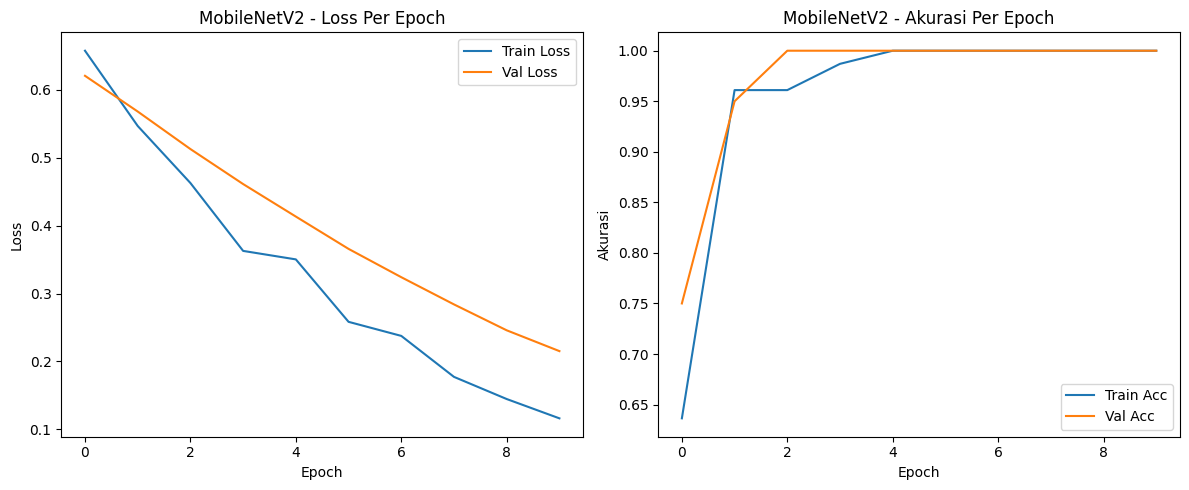

Grafik performa berhasil disimpan sebagai /content/grafik_performa.jpg


In [10]:
plt.figure(figsize=(12, 5))

# Grafik Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('MobileNetV2 - Loss Per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Grafik Akurasi
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.title('MobileNetV2 - Akurasi Per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()

plt.tight_layout()
plt.savefig('/content/grafik_performa.jpg', dpi=300, bbox_inches='tight')
plt.show()
print("Grafik performa berhasil disimpan sebagai /content/grafik_performa.jpg")

**Evaluasi Akhir pada Test Set**

In [11]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in val_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Akurasi Akhir pada Data Test/Validasi: {accuracy:.2f}%')

Akurasi Akhir pada Data Test/Validasi: 100.00%


**Visualisasi Hasil Prediksi Gambar**

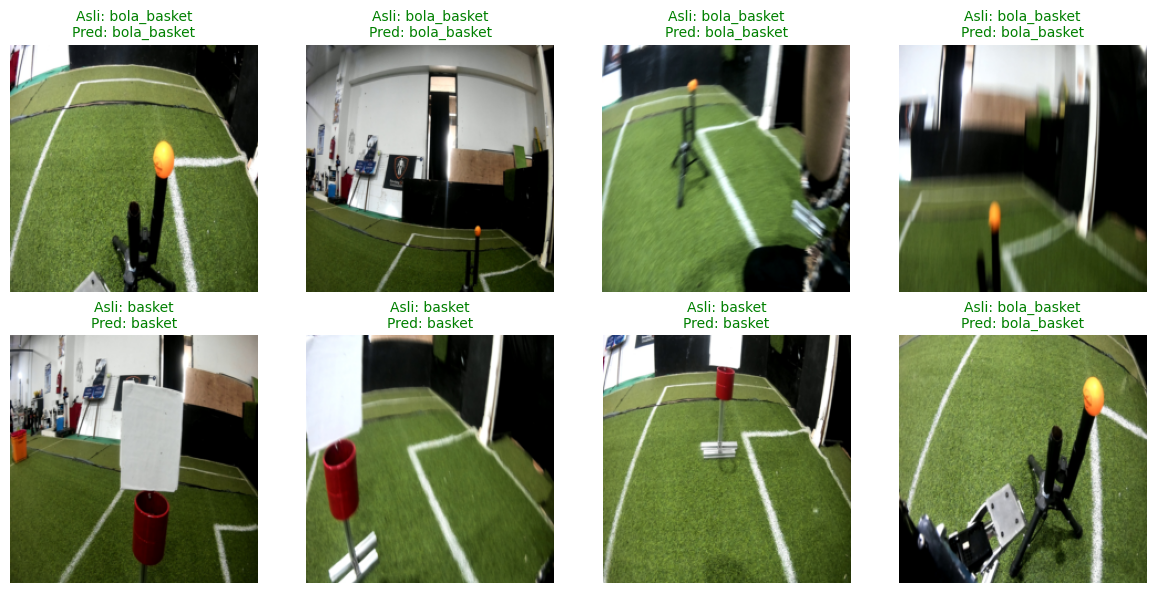

Visualisasi prediksi berhasil disimpan sebagai /content/hasil_prediksi_test.jpg


In [12]:
model.eval()
class_names = img_dataset.classes
images, labels = next(iter(val_dataloader))
images_dev = images.to(device)

with torch.no_grad():
    outputs = model(images_dev)
    _, preds = torch.max(outputs, 1)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(12, 6))
for i in range(min(8, len(images))):
    ax = plt.subplot(2, 4, i + 1)

    # Denormalisasi gambar
    img = images[i].cpu() * std + mean
    img = torch.clamp(img, 0, 1)
    img = img.permute(1, 2, 0).numpy()

    plt.imshow(img)
    true_label = class_names[labels[i].item()]
    pred_label = class_names[preds[i].item()]
    color = 'green' if true_label == pred_label else 'red'

    ax.set_title(f"Asli: {true_label}\nPred: {pred_label}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.savefig('/content/hasil_prediksi_test.jpg', dpi=300, bbox_inches='tight')
plt.show()
print("Visualisasi prediksi berhasil disimpan sebagai /content/hasil_prediksi_test.jpg")

**Unduh File MobileNetV2**

In [13]:
from google.colab import files
import os

# Daftar file artefak MobileNetV2 yang ingin diunduh
files_to_download = [
    '/content/metadata.csv',
    '/content/hasil_training/mobilenet_fine_tuning.pth',
    '/content/grafik_performa.jpg',
    '/content/hasil_prediksi_test.jpg'
]

print("Memulai proses pengunduhan file...")
for file_path in files_to_download:
    if os.path.exists(file_path):
        print(f"Mengunduh: {file_path}")
        files.download(file_path)
    else:
        print(f"File tidak ditemukan: {file_path}")

Memulai proses pengunduhan file...
Mengunduh: /content/metadata.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengunduh: /content/hasil_training/mobilenet_fine_tuning.pth


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengunduh: /content/hasil_prediksi_test.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>